In [1]:
import glob
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def calculate_tercile_flags(data, var):
    # calculate terciles to cluster indices into 3 categories: -1 (negative/cold), 0 (netural), 1 (positive/warm state)
    df = data[var].to_dataframe()
    df = df.reset_index()
    df = df.set_index('time')
    tertiles = df[var].quantile([1/3, 2/3]).to_list()
    tertiles = [-float('inf')] + tertiles + [float('inf')]

    return tertiles

In [ ]:
df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv")
plotdir = "/home/kperny/VolMIP_stratosphere/plots/flag_changes/"

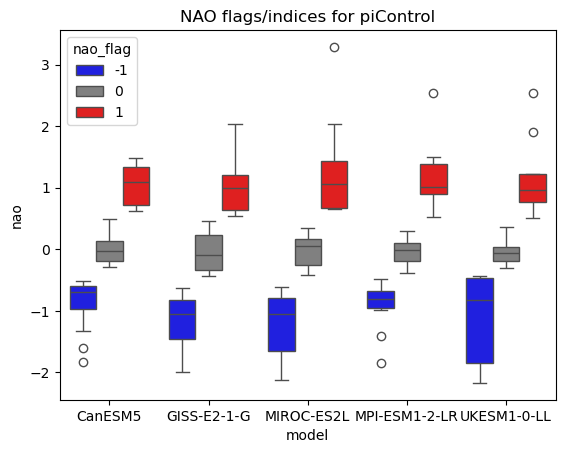

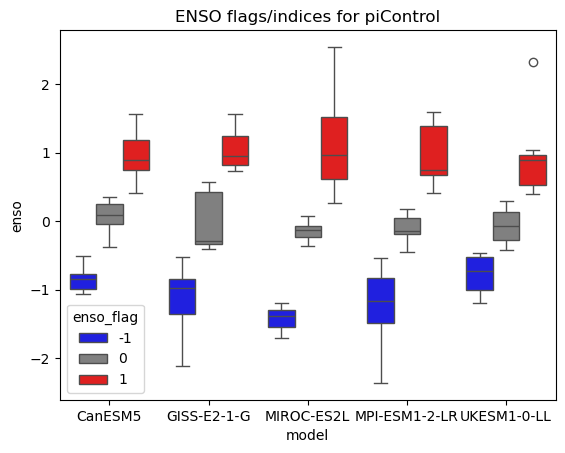

In [3]:
sns.boxplot(x="model", y="nao",
            hue="nao_flag", palette=["b", "grey", "r"],
            data=df_flags)
plt.title('NAO flags/indices for piControl')
plt.savefig(plotdir + 'background/nao_flags-indices.png', dpi=200)
plt.show()
sns.boxplot(x="model", y="enso",
            hue="enso_flag", palette=["b", "grey", "r"],
            data=df_flags)
plt.title('ENSO flags/indices for piControl')
plt.savefig(plotdir + 'background/enso_flags-indices.png', dpi=200)

/sto4/data/Intermediate/VolMIP/piControl/CanESM5/piControl_CanESM5_NAO_djf_5550-6600.nc


/tmp/ipykernel_1153982/4280357003.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


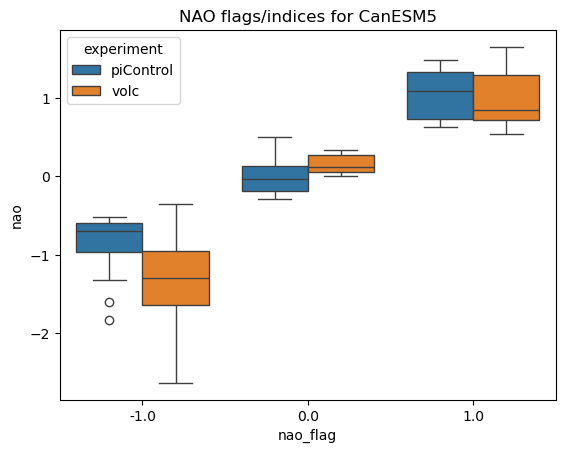

/sto4/data/Intermediate/VolMIP/piControl/MIROC-ES2L/piControl_MIROC-ES2L_NAO_djf_1850-2349.nc


/tmp/ipykernel_1153982/4280357003.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


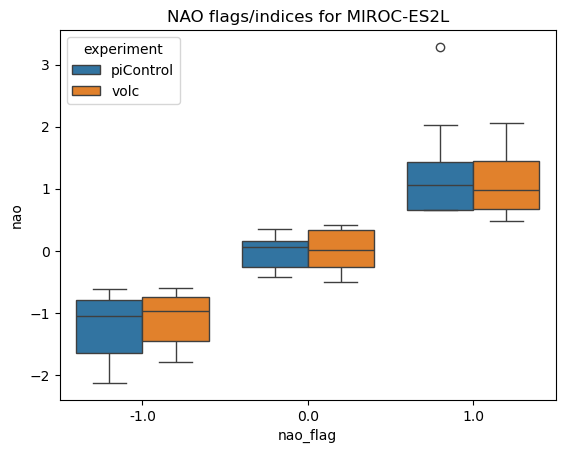

/sto4/data/Intermediate/VolMIP/piControl/MPI-ESM1-2-LR/piControl_MPI-ESM1-2-LR_NAO_djf_1850-2849.nc


/tmp/ipykernel_1153982/4280357003.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


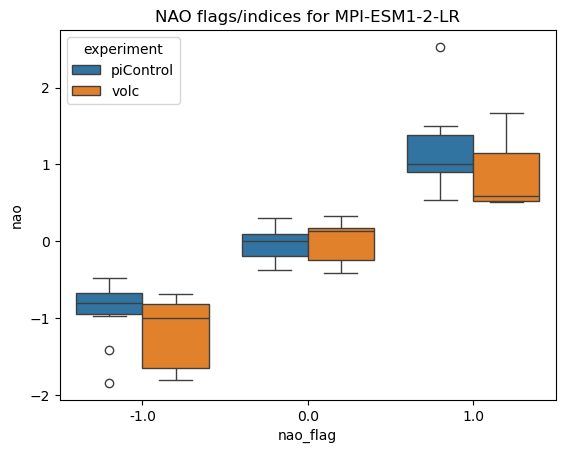

/sto4/data/Intermediate/VolMIP/piControl/GISS-E2-1-G/piControl_GISS-E2-1-G_NAO_djf_7550-8400.nc


/tmp/ipykernel_1153982/4280357003.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_1153982/4280357003.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_1153982/4280357003.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime obj

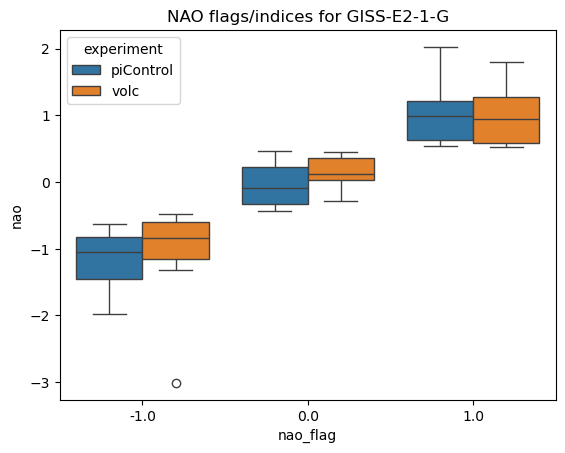

/sto4/data/Intermediate/VolMIP/piControl/UKESM1-0-LL/piControl_UKESM1-0-LL_NAO_djf_1960-3839.nc


/tmp/ipykernel_1153982/4280357003.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


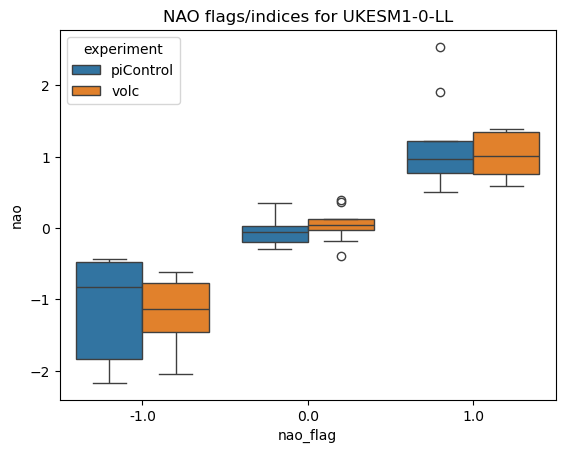

In [80]:
datadir = "/sto4/data/Intermediate/VolMIP/"
models = ['CanESM5', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'UKESM1-0-LL']

collect_df = []
for model in models:
    df_model = df_flags.where(df_flags['model'] == model).dropna()
    print(glob.glob(datadir + 'piControl/' + model + '/piControl_' + model + '_NAO_djf*.nc')[0])
    data_control = xr.open_dataset(glob.glob(datadir + 'piControl/' + model + '/piControl_' + model + '_NAO_djf*.nc')[0], decode_times=time_coder)
    tertiles = calculate_tercile_flags((data_control- data_control.mean('time') ) /  np.sqrt(data_control.var('time')), 'zg')
    nao = []
    for ens in df_model['realization']:
        data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
        nao.append((calculate_djf_mean(data_volc).sel(time='1992') - data_control.mean('time') ) /  np.sqrt(data_control.var('time')))
        
    nao_volc = xr.concat(nao, dim='realization')
    nao_volc['realization'] = df_model['realization'].values
    df_volc = nao_volc.rename({'zg': 'nao'}).nao.to_dataframe().reset_index().drop(['time', 'plev', 'lat', 'lon'], axis=1)

    df_volc['nao_flag'] = pd.cut(df_volc['nao'], bins=tertiles, labels=[-1,0,1])
    df_volc['experiment'] = 'volc'
    df_cut = df_model[['realization', 'nao', 'nao_flag']]
    df_cut['experiment'] = 'piControl'

    df = pd.concat([df_cut, df_volc])
    df['model'] = model
    collect_df.append(df)

    sns.boxplot(x="nao_flag", y="nao",
                hue="experiment", palette=['C0', 'C1'],
                data=df)
    plt.title('NAO flags/indices for ' + model)
    plt.savefig(plotdir + model + '_nao-change.png', dpi=200)
    plt.show()

In [74]:
df = pd.concat(collect_df)
df = df.set_index(['model', 'realization', 'experiment']).sort_index()
df.reset_index().to_csv("/home/kperny/VolMIP_stratosphere/tab/nao_change.csv", index=False)
df = df.reset_index().set_index(['model', 'realization']).sort_index()

In [75]:
# calculate amount of pi Control
pi_Control = df.where(df['experiment']=='piControl').dropna().drop(['experiment', 'nao'], axis=1).reset_index()
pi_Control['count'] = 1
pi_Control.groupby(['model', 'nao_flag']).sum()

realization  \
model         nao_flag                                                      
CanESM5       -1.0      r12i1p2f1r13i1p2f1r16i1p2f1r19i1p2f1r22i1p2f1r...   
               0.0      r10i1p2f1r18i1p2f1r1i1p2f1r21i1p2f1r29i1p2f1r2...   
               1.0      r11i1p2f1r14i1p2f1r15i1p2f1r17i1p2f1r20i1p2f1r...   
GISS-E2-1-G   -1.0      r18i1p1f2r20i1p1f2r21i1p1f2r25i1p1f2r28i1p1f2r...   
               0.0      r10i1p1f2r12i1p1f2r13i1p1f2r14i1p1f2r1i1p1f2r2...   
               1.0      r11i1p1f2r15i1p1f2r16i1p1f2r17i1p1f2r19i1p1f2r...   
MIROC-ES2L    -1.0      r14i1p1f2r22i1p1f2r23i1p1f2r2i1p1f2r6i1p1f2r7i...   
               0.0      r10i1p1f2r11i1p1f2r16i1p1f2r17i1p1f2r18i1p1f2r...   
               1.0      r12i1p1f2r13i1p1f2r15i1p1f2r19i1p1f2r1i1p1f2r2...   
MPI-ESM1-2-LR -1.0      r11i1p1f1r12i1p1f1r16i1p1f1r18i1p1f1r1i1p1f1r2...   
               0.0      r13i1p1f1r14i1p1f1r15i1p1f1r17i1p1f1r19i1p1f1r...   
               1.0      r10i1p1f1r20i1p1f1r25i1p1f1r2i1p1f1r4i1p1f1r7i...   
UKESM1-0-LL   -1.0      r10i1p1f2r13i1p1f2r14i1p1f2r15i1p1f2r19i1p1f2r...   
               0.0      r16i1p1f2r21i1p1f2r22i1p1f2r24i1p1f2r25i1p1f2r...   
               1.0      r11i1p1f2r17i1p1f2r18i1p1f2r20i1p1f2r26i1p1f2r...   

                        count  
model         nao_flag         
CanESM5       -1.0         13  
               0.0         15  
               1.0         12  
GISS-E2-1-G   -1.0          8  
               0.0         19  
               1.0         13  
MIROC-ES2L    -1.0          6  
               0.0          8  
               1.0         11  
MPI-ESM1-2-LR -1.0         10  
               0.0          7  
               1.0          8  
UKESM1-0-LL   -1.0          7  
               0.0          8  
               1.0          9

In [77]:
# how many nao- in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['nao_flag'] == -1)).dropna().drop(['experiment', 'nao', 'nao_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'nao'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('nao_flag').sum())

CanESM5
          count
nao_flag       
-1.0          6
 0.0          1
 1.0          6
GISS-E2-1-G
          count
nao_flag       
-1.0          3
 1.0          5
MIROC-ES2L
          count
nao_flag       
-1.0          3
 0.0          3
MPI-ESM1-2-LR
          count
nao_flag       
-1.0          3
 0.0          4
 1.0          3
UKESM1-0-LL
          count
nao_flag       
0.0           4
1.0           3


In [78]:
# how many nao0 in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['nao_flag'] == 0)).dropna().drop(['experiment', 'nao', 'nao_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'nao'], axis=1)
df_volc['count'] = 1
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('nao_flag').sum())

CanESM5
          count
nao_flag       
-1.0          7
 0.0          4
 1.0          4
GISS-E2-1-G
          count
nao_flag       
-1.0          2
 0.0          9
 1.0          8
MIROC-ES2L
          count
nao_flag       
-1.0          1
 0.0          3
 1.0          4
MPI-ESM1-2-LR
          count
nao_flag       
-1.0          3
 0.0          1
 1.0          3
UKESM1-0-LL
          count
nao_flag       
-1.0          2
 0.0          3
 1.0          3


In [79]:
# how many nao+ in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['nao_flag'] == 1)).dropna().drop(['experiment', 'nao', 'nao_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'nao'], axis=1)
df_volc['count'] = 1
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('nao_flag').sum())

CanESM5
          count
nao_flag       
-1.0          6
 0.0          2
 1.0          4
GISS-E2-1-G
          count
nao_flag       
-1.0          3
 0.0          6
 1.0          4
MIROC-ES2L
          count
nao_flag       
-1.0          4
 0.0          3
 1.0          4
MPI-ESM1-2-LR
          count
nao_flag       
-1.0          2
 0.0          2
 1.0          4
UKESM1-0-LL
          count
nao_flag       
-1.0          4
 0.0          2
 1.0          3


/tmp/ipykernel_1153982/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


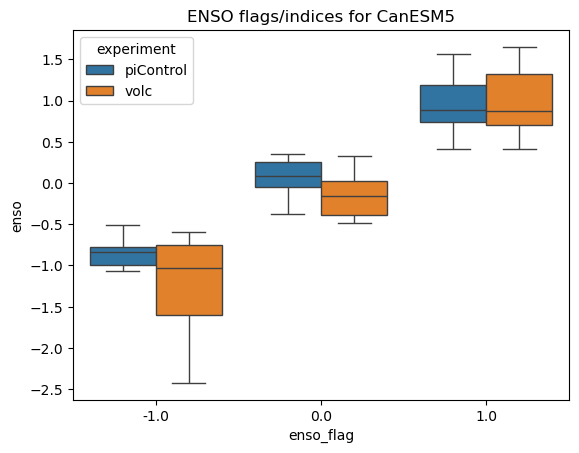

/tmp/ipykernel_1153982/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


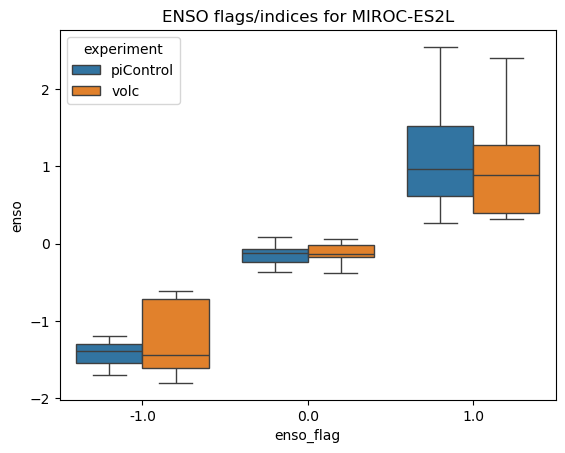

/tmp/ipykernel_1153982/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


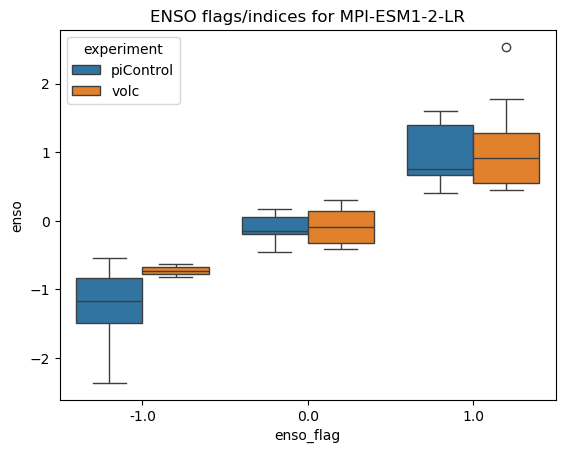

/tmp/ipykernel_1153982/2794516501.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/ENSO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_1153982/2794516501.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/ENSO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_1153982/2794516501.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime o

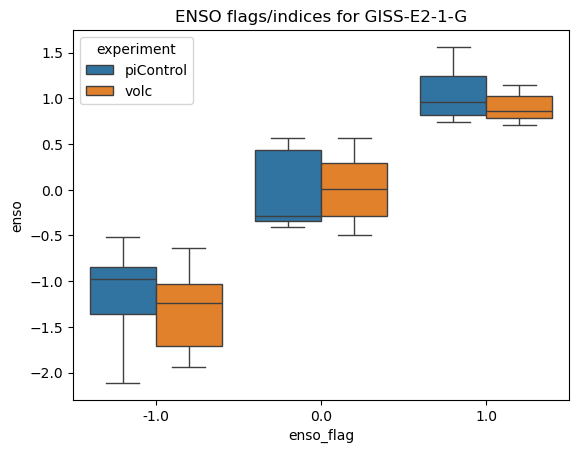

/tmp/ipykernel_1153982/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


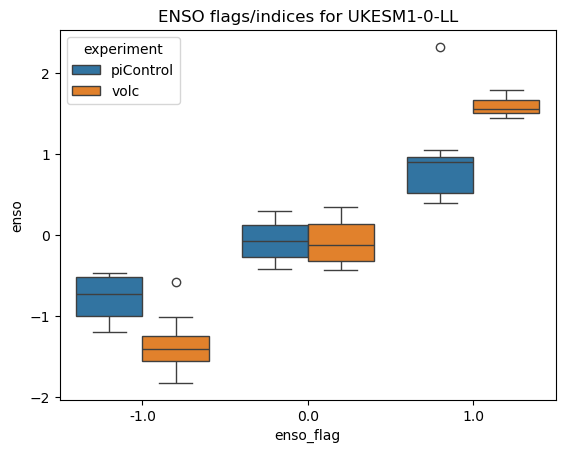

In [82]:
datadir = "/sto4/data/Intermediate/VolMIP/"
models = ['CanESM5', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'UKESM1-0-LL']

collect_df = []
for model in models:
    df_model = df_flags.where(df_flags['model'] == model).dropna()

    data_control = xr.open_dataset(glob.glob(datadir + 'piControl/' + model + '/piControl_' + model + '_Nino34_djf*.nc')[0], decode_times=time_coder)
    tertiles = calculate_tercile_flags((data_control- data_control.mean('time') ) /  np.sqrt(data_control.var('time')), 'tos')
    enso = []
    for ens in df_model['realization']:
        data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/ENSO_*' + ens + '*_fixed_dates.nc')[0])
        enso.append((calculate_djf_mean(data_volc).sel(time='1992') - data_control.mean('time') ) /  np.sqrt(data_control.var('time')))
        
    enso_volc = xr.concat(enso, dim='realization')
    enso_volc['realization'] = df_model['realization'].values
    df_volc = enso_volc.rename({'tos': 'enso'}).enso.to_dataframe().reset_index().drop(['time','lat', 'lon'], axis=1)

    df_volc['enso_flag'] = pd.cut(df_volc['enso'], bins=tertiles, labels=[-1,0,1])
    df_volc['experiment'] = 'volc'
    df_cut = df_model[['realization', 'enso', 'enso_flag']]
    df_cut['experiment'] = 'piControl'

    df = pd.concat([df_cut, df_volc])
    df['model'] = model
    collect_df.append(df)

    sns.boxplot(x="enso_flag", y="enso",
                hue="experiment", palette=['C0', 'C1'],
                data=df)
    plt.title('ENSO flags/indices for ' + model)
    plt.savefig(plotdir + model + '_enso-change.png', dpi=200)
    plt.show()

In [83]:
df = pd.concat(collect_df)
df = df.set_index(['model', 'realization', 'experiment']).sort_index()
df.reset_index().to_csv("/home/kperny/VolMIP_stratosphere/tab/enso_change.csv", index=False)
df = df.reset_index().set_index(['model', 'realization']).sort_index()

In [84]:
df

experiment      enso  enso_flag
model       realization                                
CanESM5     r10i1p2f1    piControl  0.216737        0.0
            r10i1p2f1         volc -0.490471        0.0
            r11i1p2f1    piControl -1.069283       -1.0
            r11i1p2f1         volc -1.723579       -1.0
            r12i1p2f1    piControl  0.009603        0.0
...                            ...       ...        ...
UKESM1-0-LL r7i1p1f2          volc  1.440647        1.0
            r8i1p1f2     piControl  2.320614        1.0
            r8i1p1f2          volc -0.177838        0.0
            r9i1p1f2     piControl -0.213546        0.0
            r9i1p1f2          volc -0.427529        0.0

[308 rows x 3 columns]

In [85]:
# calculate amount of pi Control
pi_Control = df.where(df['experiment']=='piControl').dropna().drop(['experiment', 'enso'], axis=1).reset_index()
pi_Control['count'] = 1
pi_Control.groupby(['model', 'enso_flag']).sum()

realization  \
model         enso_flag                                                      
CanESM5       -1.0       r11i1p2f1r17i1p2f1r1i1p2f1r29i1p2f1r30i1p2f1r3...   
               0.0       r10i1p2f1r12i1p2f1r13i1p2f1r15i1p2f1r18i1p2f1r...   
               1.0       r14i1p2f1r16i1p2f1r19i1p2f1r20i1p2f1r22i1p2f1r...   
GISS-E2-1-G   -1.0       r11i1p1f2r13i1p1f2r14i1p1f2r16i1p1f2r1i1p1f2r2...   
               0.0       r10i1p1f2r12i1p1f2r17i1p1f2r18i1p1f2r19i1p1f2r...   
               1.0       r15i1p1f2r20i1p1f2r23i1p1f2r24i1p1f2r25i1p1f2r...   
MIROC-ES2L    -1.0                               r10i1p1f2r6i1p1f2r7i1p1f2   
               0.0       r11i1p1f2r16i1p1f2r19i1p1f2r21i1p1f2r25i1p1f2r...   
               1.0       r12i1p1f2r13i1p1f2r14i1p1f2r15i1p1f2r17i1p1f2r...   
MPI-ESM1-2-LR -1.0       r10i1p1f1r11i1p1f1r13i1p1f1r15i1p1f1r17i1p1f1r...   
               0.0       r19i1p1f1r20i1p1f1r21i1p1f1r24i1p1f1r2i1p1f1r3...   
               1.0       r12i1p1f1r14i1p1f1r16i1p1f1r1i1p1f1r25i1p1f1r4...   
UKESM1-0-LL   -1.0       r11i1p1f2r16i1p1f2r19i1p1f2r20i1p1f2r26i1p1f2r...   
               0.0       r10i1p1f2r13i1p1f2r15i1p1f2r17i1p1f2r18i1p1f2r...   
               1.0       r14i1p1f2r21i1p1f2r27i1p1f2r3i1p1f2r5i1p1f2r6i...   

                         count  
model         enso_flag         
CanESM5       -1.0          12  
               0.0          17  
               1.0          11  
GISS-E2-1-G   -1.0          18  
               0.0          11  
               1.0          11  
MIROC-ES2L    -1.0           3  
               0.0          10  
               1.0          12  
MPI-ESM1-2-LR -1.0          10  
               0.0           7  
               1.0           8  
UKESM1-0-LL   -1.0           6  
               0.0          10  
               1.0           8

In [86]:
# how many nao- in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['enso_flag'] == -1)).dropna().drop(['experiment', 'enso', 'enso_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'enso'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('enso_flag').sum())

CanESM5
           count
enso_flag       
-1.0          10
 0.0           2
GISS-E2-1-G
           count
enso_flag       
-1.0          17
 0.0           1
MIROC-ES2L
           count
enso_flag       
-1.0           3
MPI-ESM1-2-LR
           count
enso_flag       
-1.0           2
 0.0           7
 1.0           1
UKESM1-0-LL
           count
enso_flag       
-1.0           5
 0.0           1


In [87]:
# how many nao0 in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['enso_flag'] == 0)).dropna().drop(['experiment', 'enso', 'enso_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'enso'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('enso_flag').sum())

CanESM5
           count
enso_flag       
-1.0           6
 0.0           8
 1.0           3
GISS-E2-1-G
           count
enso_flag       
-1.0           1
 0.0           7
 1.0           3
MIROC-ES2L
           count
enso_flag       
-1.0           1
 0.0           9
MPI-ESM1-2-LR
           count
enso_flag       
0.0            3
1.0            4
UKESM1-0-LL
           count
enso_flag       
-1.0           3
 0.0           5
 1.0           2


In [89]:
# how many enso+ in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['enso_flag'] == 1)).dropna().drop(['experiment', 'enso', 'enso_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'enso'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('enso_flag').sum())

CanESM5
           count
enso_flag       
-1.0           3
 0.0           3
 1.0           5
GISS-E2-1-G
           count
enso_flag       
0.0            8
1.0            3
MIROC-ES2L
           count
enso_flag       
-1.0           1
 0.0           1
 1.0          10
MPI-ESM1-2-LR
           count
enso_flag       
0.0            3
1.0            5
UKESM1-0-LL
           count
enso_flag       
-1.0           3
 0.0           4
 1.0           1
